# Taller 3: EDA de armas de Elden Ring
Los datos vienen de la API eldenring.fanapis.com y están guardados crudos en MongoDB
(base `taller3_db`, colección `raw_data`). En este notebook los leo, selecciono variables,
los limpio y hago el análisis exploratorio.

## 1. Conexión a MongoDB

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

client = MongoClient("mongodb://localhost:27017/")
col = client["taller3_db"]["raw_data"]
print("Documentos en la colección:", col.count_documents({}))

Documentos en la colección: 307


## 2. Lectura de los datos crudos
Leo todos los documentos de la colección. Reviso uno de ejemplo para ver su estructura,
porque `attack`, `defence`, `requiredAttributes` y `scalesWith` vienen como listas anidadas.

In [2]:
docs = list(col.find())
print("Documentos leídos:", len(docs))
docs[0]

Documentos leídos: 307


{'_id': '17f69c35d2cl0i1oh7zuqfb3mdvsj',
 'id': '17f69c35d2cl0i1oh7zuqfb3mdvsj',
 'name': 'Hand Axe',
 'image': 'https://eldenring.fanapis.com/images/weapons/17f69c35d2cl0i1oh7zuqfb3mdvsj.png',
 'description': 'Commonly known as a hatchet, this smaller variety of axe is an everyday work tool. Despite its short reach, it is easy to handle, exceling in successive attacks.',
 'attack': [{'name': 'Phy', 'amount': 113},
  {'name': 'Mag', 'amount': 0},
  {'name': 'Fire', 'amount': 0},
  {'name': 'Ligt', 'amount': 0},
  {'name': 'Holy', 'amount': 0},
  {'name': 'Crit', 'amount': 100}],
 'defence': [{'name': 'Phy', 'amount': 42},
  {'name': 'Mag', 'amount': 28},
  {'name': 'Fire', 'amount': 28},
  {'name': 'Ligt', 'amount': 28},
  {'name': 'Holy', 'amount': 28},
  {'name': 'Boost', 'amount': 28}],
 'scalesWith': [{'name': 'Str', 'scaling': 'D'},
  {'name': 'Dex', 'scaling': 'D'}],
 'requiredAttributes': [{'name': 'Str', 'amount': 9},
  {'name': 'Dex', 'amount': 8}],
 'category': 'Axe',
 'weigh

## 3. Selección de variables
Selecciono 8 variables relevantes: nombre, categoría, peso, ataque físico, ataque crítico,
fuerza requerida, destreza requerida y escalado con fuerza. Las listas anidadas se aplanan
a columnas simples.


In [3]:
def a_dict(lista):
    """Convierte [{'name': 'Str', 'amount': 20}] en {'Str': 20}."""
    return {x["name"]: x.get("amount", x.get("scaling")) for x in (lista or [])}

filas = []
for d in docs:
    atk = a_dict(d.get("attack"))
    req = a_dict(d.get("requiredAttributes"))
    esc = a_dict(d.get("scalesWith"))
    filas.append({
        "nombre": d.get("name"),
        "categoria": d.get("category"),
        "peso": d.get("weight"),
        "ataque_fisico": atk.get("Phy"),
        "ataque_critico": atk.get("Crit"),
        "req_fuerza": req.get("Str"),
        "req_destreza": req.get("Dex"),
        "escala_fuerza": esc.get("Str"),
    })

df = pd.DataFrame(filas)
df.shape

(307, 8)

## 4. Limpieza
- Convierto las columnas numéricas a número (lo que no se pueda convertir queda como nulo).
- Si un arma no tiene requisito de fuerza o destreza, lo trato como 0.
- Si un arma no escala con fuerza, lo marco como "Sin escala".
- Elimino filas duplicadas.

In [4]:
for c in ["peso", "ataque_fisico", "ataque_critico", "req_fuerza", "req_destreza"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df[["req_fuerza", "req_destreza"]] = df[["req_fuerza", "req_destreza"]].fillna(0)
df["escala_fuerza"] = df["escala_fuerza"].fillna("Sin escala")

print("Duplicados:", df.duplicated().sum())
df = df.drop_duplicates()
df.shape


Duplicados: 1


(306, 8)

## 5. Inspección básica
Primeras filas, tipos de datos y conteo de nulos.

In [5]:
df.head()

,nombre,categoria,peso,ataque_fisico,ataque_critico,req_fuerza,req_destreza,escala_fuerza
0,Hand Axe,Axe,3.5,113.0,100,9.0,8.0,D
1,Jawbone Axe,Axe,5.5,124.0,100,14.0,8.0,D
2,Forked Hatchet,Axe,2.5,101.0,100,9.0,14.0,D
3,Iron Cleaver,Axe,6.0,120.0,100,15.0,7.0,C
4,Battle Axe,Axe,4.5,123.0,100,12.0,8.0,D


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 306 entries, 0 to 306
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   nombre          306 non-null    str    
 1   categoria       306 non-null    str    
 2   peso            306 non-null    float64
 3   ataque_fisico   305 non-null    float64
 4   ataque_critico  306 non-null    int64  
 5   req_fuerza      306 non-null    float64
 6   req_destreza    306 non-null    float64
 7   escala_fuerza   306 non-null    str    
dtypes: float64(4), int64(1), str(3)
memory usage: 21.5 KB


In [7]:
df.isnull().sum()


nombre            0
categoria         0
peso              0
ataque_fisico     1
ataque_critico    0
req_fuerza        0
req_destreza      0
escala_fuerza     0
dtype: int64

## 6. Insights numéricos
Cinco datos relevantes sobre las armas.

In [8]:
# 1. Total de armas y de categorías
print(f"1. Hay {len(df)} armas en {df['categoria'].nunique()} categorías.")

# 2. Categoría con más armas
conteo_cat = df["categoria"].value_counts()
print(f"2. La categoría más común es {conteo_cat.idxmax()} con {conteo_cat.max()} armas.")

# 3. Arma con mayor ataque físico
mejor = df.loc[df["ataque_fisico"].idxmax()]
print(f"3. El arma con más ataque físico es {mejor['nombre']} ({mejor['ataque_fisico']}).")

# 4. Peso promedio y arma más pesada
pesada = df.loc[df["peso"].idxmax()]
print(f"4. El peso promedio es {df['peso'].mean():.2f}. La más pesada es {pesada['nombre']} ({pesada['peso']}).")

# 5. Armas con escalado A o B en fuerza
n_ab = df["escala_fuerza"].isin(["A", "B"]).sum()
print(f"5. {n_ab} armas escalan con Fuerza en grado A o B.")

1. Hay 306 armas en 31 categorías.
2. La categoría más común es Greatsword con 20 armas.
3. El arma con más ataque físico es Jar Cannon (192.0).
4. El peso promedio es 7.09. La más pesada es Giant-crusher (26.5).
5. 3 armas escalan con Fuerza en grado A o B.


## 7. Visualizaciones
### Gráfico 1: proporción de armas por categoría
Agrupo las categorías menos frecuentes en "Otros" para que la torta sea legible.


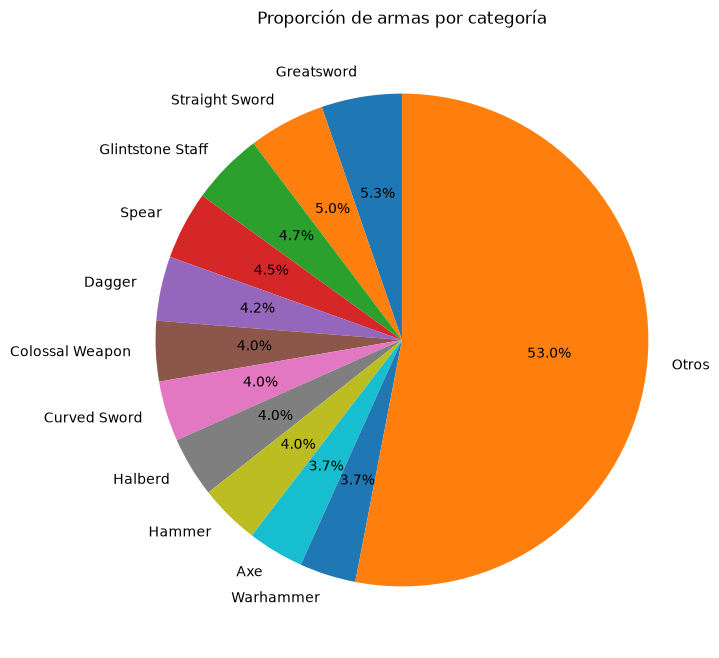

In [17]:
conteo = df["categoria"].value_counts()
principales = conteo.head(11)
otros = conteo.iloc[6:].sum()
datos = pd.concat([principales, pd.Series({"Otros": otros})])

plt.figure(figsize=(8, 8))
plt.pie(datos, labels=datos.index, autopct="%1.1f%%", startangle=90)
plt.title("Proporción de armas por categoría")
plt.show()